In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/telco_churn_raw.csv")

# Fix TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Drop the 11 broken rows (they're new customers, not useful for churn prediction)
df = df.dropna(subset=['TotalCharges'])

# Convert target to binary 0/1 for later
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(f"Clean shape: {df.shape}")
print(f"Churn rate: {df['Churn'].mean():.2%}")

Clean shape: (7032, 21)
Churn rate: 26.58%


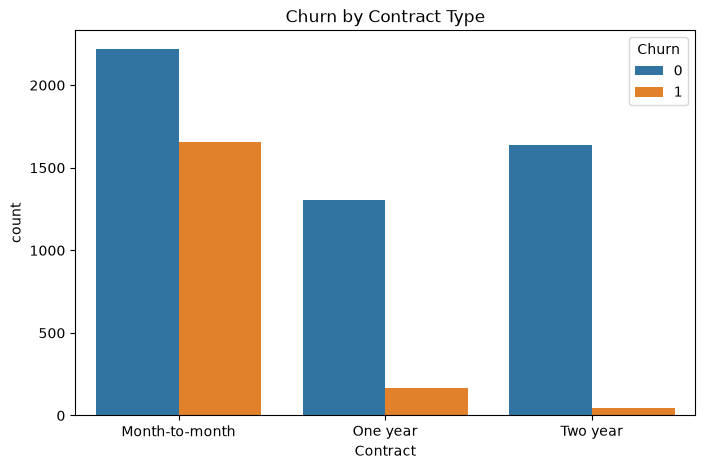

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Churn by Contract Type')
plt.show()

In [ ]:
df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)

Contract
Month-to-month    0.427097
One year          0.112772
Two year          0.028487
Name: Churn, dtype: float64

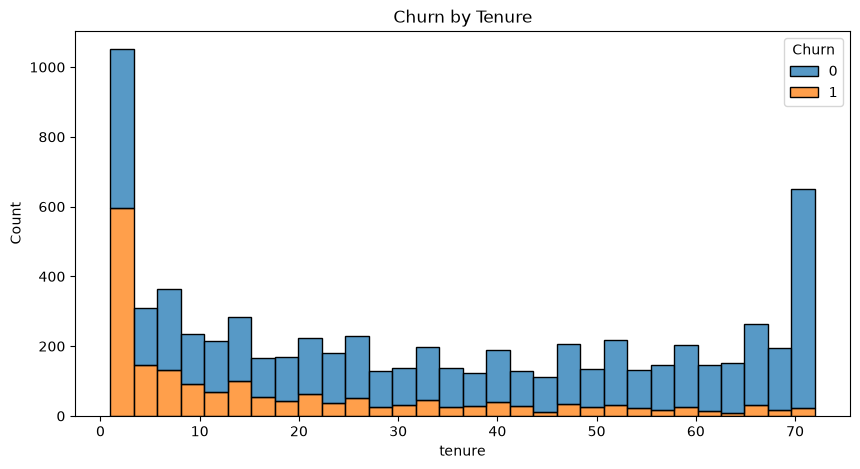

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack')
plt.title('Churn by Tenure')
plt.show()

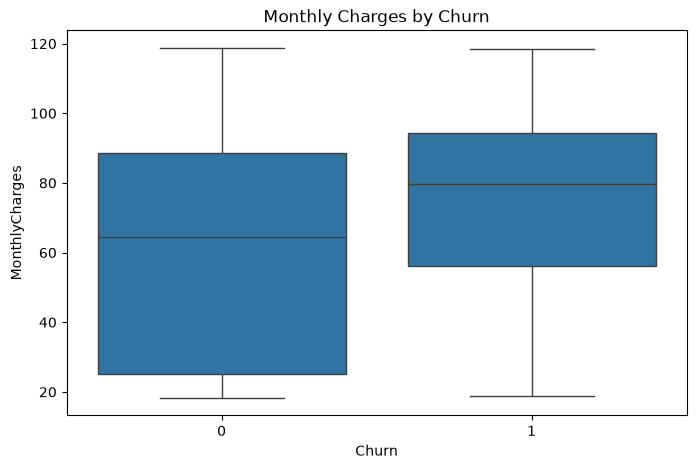

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges by Churn')
plt.show()